## 1. Import Libraries

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D
from tensorflow.keras.layers import Flatten, Dense, Dropout

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


## 2. Load Dataset

In [9]:
# Put cats(1)(2).csv in the same folder as this notebook
df = pd.read_csv("cats(1).csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (297, 11)


,48076,26989072,https://www.petfinder.com/cat/jupiter-26989072/qc/montreal/chatopia-formerly-animal-adoption-montreal-qc35/?referrer_id=3830981a-ad4c-4f85-872c-ca9edc50a67e,Cat,Adult,Male,Medium,Unnamed: 7,Persian,"[{'small': 'https://dl5zpyw5k3jeb.cloudfront.net/photos/pets/26989072/1/?bust=1377857208&width=100', 'medium': 'https://dl5zpyw5k3jeb.cloudfront.net/photos/pets/26989072/1/?bust=1377857208&width=300', 'large': 'https://dl5zpyw5k3jeb.cloudfront.net/photos/pets/26989072/1/?bust=1377857208&width=600', 'full': 'https://dl5zpyw5k3jeb.cloudfront.net/photos/pets/26989072/1/?bust=1377857208'}, {'small': 'https://dl5zpyw5k3jeb.cloudfront.net/photos/pets/26989072/2/?bust=1377857210&width=100', 'medium': 'https://dl5zpyw5k3jeb.cloudfront.net/photos/pets/26989072/2/?bust=1377857210&width=300', 'large': 'https://dl5zpyw5k3jeb.cloudfront.net/photos/pets/26989072/2/?bust=1377857210&width=600', 'full': 'https://dl5zpyw5k3jeb.cloudfront.net/photos/pets/26989072/2/?bust=1377857210'}]","['https://dl5zpyw5k3jeb.cloudfront.net/photos/pets/26989072/1/?bust=1377857208&width=300', 'https://dl5zpyw5k3jeb.cloudfront.net/photos/pets/26989072/2/?bust=1377857210&width=300']"
0,48077,26979449,https://www.petfinder.com/cat/elliot-26979449/...,Cat,Adult,Male,Medium,Long,Persian,[{'small': 'https://dl5zpyw5k3jeb.cloudfront.n...,['https://dl5zpyw5k3jeb.cloudfront.net/photos/...
1,48078,26974960,https://www.petfinder.com/cat/zarro-26974960/m...,Cat,Adult,Male,Small,Medium,Persian,[{'small': 'https://dl5zpyw5k3jeb.cloudfront.n...,['https://dl5zpyw5k3jeb.cloudfront.net/photos/...
2,48079,26973986,https://www.petfinder.com/cat/snickers-2697398...,Cat,Adult,Female,Small,NaN,Persian,[{'small': 'https://dl5zpyw5k3jeb.cloudfront.n...,['https://dl5zpyw5k3jeb.cloudfront.net/photos/...
3,48080,26972127,https://www.petfinder.com/cat/ms-bigglesworth-...,Cat,Senior,Female,Small,Long,Persian,[{'small': 'https://dl5zpyw5k3jeb.cloudfront.n...,['https://dl5zpyw5k3jeb.cloudfront.net/photos/...
4,48081,26961377,https://www.petfinder.com/cat/midnight-2696137...,Cat,Adult,Female,Medium,Long,Persian,[{'small': 'https://dl5zpyw5k3jeb.cloudfront.n...,['https://dl5zpyw5k3jeb.cloudfront.net/photos/...


## 3. Explore Dataset

In [10]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())


Columns:
['48076', '26989072', 'https://www.petfinder.com/cat/jupiter-26989072/qc/montreal/chatopia-formerly-animal-adoption-montreal-qc35/?referrer_id=3830981a-ad4c-4f85-872c-ca9edc50a67e', 'Cat', 'Adult', 'Male', 'Medium', 'Unnamed: 7', 'Persian', "[{'small': 'https://dl5zpyw5k3jeb.cloudfront.net/photos/pets/26989072/1/?bust=1377857208&width=100', 'medium': 'https://dl5zpyw5k3jeb.cloudfront.net/photos/pets/26989072/1/?bust=1377857208&width=300', 'large': 'https://dl5zpyw5k3jeb.cloudfront.net/photos/pets/26989072/1/?bust=1377857208&width=600', 'full': 'https://dl5zpyw5k3jeb.cloudfront.net/photos/pets/26989072/1/?bust=1377857208'}, {'small': 'https://dl5zpyw5k3jeb.cloudfront.net/photos/pets/26989072/2/?bust=1377857210&width=100', 'medium': 'https://dl5zpyw5k3jeb.cloudfront.net/photos/pets/26989072/2/?bust=1377857210&width=300', 'large': 'https://dl5zpyw5k3jeb.cloudfront.net/photos/pets/26989072/2/?bust=1377857210&width=600', 'full': 'https://dl5zpyw5k3jeb.cloudfront.net/photos/pets/269

## 4. Rename Columns

The CSV may not have convenient column names, so this cell detects the expected 11-column structure and assigns readable names.

In [11]:
if len(df.columns) == 11:
    df.columns = [
        "id",
        "pet_id",
        "url",
        "animal",
        "age",
        "gender",
        "size",
        "coat_length",
        "breed",
        "image_info",
        "image_urls"
    ]

display(df.head())
print("Columns:", df.columns.tolist())


,id,pet_id,url,animal,age,gender,size,coat_length,breed,image_info,image_urls
0,48077,26979449,https://www.petfinder.com/cat/elliot-26979449/...,Cat,Adult,Male,Medium,Long,Persian,[{'small': 'https://dl5zpyw5k3jeb.cloudfront.n...,['https://dl5zpyw5k3jeb.cloudfront.net/photos/...
1,48078,26974960,https://www.petfinder.com/cat/zarro-26974960/m...,Cat,Adult,Male,Small,Medium,Persian,[{'small': 'https://dl5zpyw5k3jeb.cloudfront.n...,['https://dl5zpyw5k3jeb.cloudfront.net/photos/...
2,48079,26973986,https://www.petfinder.com/cat/snickers-2697398...,Cat,Adult,Female,Small,NaN,Persian,[{'small': 'https://dl5zpyw5k3jeb.cloudfront.n...,['https://dl5zpyw5k3jeb.cloudfront.net/photos/...
3,48080,26972127,https://www.petfinder.com/cat/ms-bigglesworth-...,Cat,Senior,Female,Small,Long,Persian,[{'small': 'https://dl5zpyw5k3jeb.cloudfront.n...,['https://dl5zpyw5k3jeb.cloudfront.net/photos/...
4,48081,26961377,https://www.petfinder.com/cat/midnight-2696137...,Cat,Adult,Female,Medium,Long,Persian,[{'small': 'https://dl5zpyw5k3jeb.cloudfront.n...,['https://dl5zpyw5k3jeb.cloudfront.net/photos/...


Columns: ['id', 'pet_id', 'url', 'animal', 'age', 'gender', 'size', 'coat_length', 'breed', 'image_info', 'image_urls']


## 5. Select Features and Target

We use age, gender, size, and coat length as input features, and breed as the target.

In [12]:
features = ["age", "gender", "size", "coat_length"]
target = "breed"

# Remove rows with missing values in selected columns
data = df[features + [target]].dropna().copy()

X = data[features]
y = data[target]

print("Number of samples:", len(data))
print("\nTarget classes:")
print(y.value_counts())


Number of samples: 202

Target classes:
breed
Persian       92
Pixiebob      79
Ragamuffin    31
Name: count, dtype: int64


## 6. Encode Categorical Features and Target

In [13]:
# Convert categorical input columns to numeric values
X = pd.get_dummies(X, columns=features)

# Convert target labels to integers
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Number of input features:", X.shape[1])
print("Target classes:")
print(label_encoder.classes_)


Number of input features: 13
Target classes:
['Persian' 'Pixiebob' 'Ragamuffin']


## 7. Train/Test Split

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 161
Testing samples: 41


## 8. Standardize Input Features

In [15]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Standardization completed.")


Standardization completed.


## 9. Prepare Data for 1D CNN

Because the CSV contains tabular features rather than images, we use a **1D CNN**.

In [16]:
X_train_cnn = X_train_scaled.reshape(
    X_train_scaled.shape[0],
    X_train_scaled.shape[1],
    1
)

X_test_cnn = X_test_scaled.reshape(
    X_test_scaled.shape[0],
    X_test_scaled.shape[1],
    1
)

num_classes = len(label_encoder.classes_)

print("CNN input shape:", X_train_cnn.shape)
print("Number of classes:", num_classes)


CNN input shape: (161, 13, 1)
Number of classes: 3


## 10. Create CNN Models

In [17]:
def create_cnn_model_1(input_shape, num_classes):
    model = Sequential([
        Conv1D(32, 3, activation="relu", padding="same",
               input_shape=input_shape),
        MaxPooling1D(2),
        Flatten(),
        Dense(32, activation="relu"),
        Dropout(0.2),
        Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


def create_cnn_model_2(input_shape, num_classes):
    model = Sequential([
        Conv1D(32, 3, activation="relu", padding="same",
               input_shape=input_shape),
        MaxPooling1D(2),
        Conv1D(64, 3, activation="relu", padding="same"),
        MaxPooling1D(2),
        Flatten(),
        Dense(64, activation="relu"),
        Dropout(0.3),
        Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


def create_cnn_model_3(input_shape, num_classes):
    model = Sequential([
        Conv1D(32, 3, activation="relu", padding="same",
               input_shape=input_shape),
        Conv1D(64, 3, activation="relu", padding="same"),
        MaxPooling1D(2),
        Conv1D(128, 3, activation="relu", padding="same"),
        MaxPooling1D(2),
        Flatten(),
        Dense(128, activation="relu"),
        Dropout(0.3),
        Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


## 11. CNN Configuration 1

In [18]:
model1 = create_cnn_model_1(
    X_train_cnn.shape[1:],
    num_classes
)

model1.summary()

history1 = model1.fit(
    X_train_cnn,
    y_train,
    validation_split=0.20,
    epochs=10,
    batch_size=16,
    verbose=1
)

loss1, accuracy1 = model1.evaluate(
    X_test_cnn,
    y_test,
    verbose=0
)

print("CNN Configuration 1 Test Accuracy:", accuracy1)


c:\Users\film\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 13, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 6, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         6,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,403 (25.01 KB)

 Trainable params: 6,403 (25.01 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.5547 - loss: 1.0280 - val_accuracy: 0.6667 - val_loss: 0.9493
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7188 - loss: 0.8964 - val_accuracy: 0.6970 - val_loss: 0.9129
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7266 - loss: 0.8348 - val_accuracy: 0.6970 - val_loss: 0.8621
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7344 - loss: 0.7909 - val_accuracy: 0.6970 - val_loss: 0.8594
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7578 - loss: 0.7602 - val_accuracy: 0.6970 - val_loss: 0.8372
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7422 - loss: 0.7068 - val_accuracy: 0.6970 - val_loss: 0.8235
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7578 - loss: 0.6564 - val_accuracy: 0.6970 - val_loss: 0.8010
Epoch 8/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7500 - loss: 0.6355 - val_accuracy: 0.6970 - val_loss: 0.8101
Epoch 9

## 12. CNN Configuration 2

In [19]:
model2 = create_cnn_model_2(
    X_train_cnn.shape[1:],
    num_classes
)

model2.summary()

history2 = model2.fit(
    X_train_cnn,
    y_train,
    validation_split=0.20,
    epochs=10,
    batch_size=16,
    verbose=1
)

loss2, accuracy2 = model2.evaluate(
    X_test_cnn,
    y_test,
    verbose=0
)

print("CNN Configuration 2 Test Accuracy:", accuracy2)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_1 (Conv1D)               │ (None, 13, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 6, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 6, 64)          │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 3, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,883 (73.76 KB)

 Trainable params: 18,883 (73.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.4922 - loss: 1.0394 - val_accuracy: 0.3636 - val_loss: 1.0079
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5781 - loss: 0.9629 - val_accuracy: 0.6970 - val_loss: 0.9557
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7031 - loss: 0.8658 - val_accuracy: 0.6970 - val_loss: 0.8811
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7109 - loss: 0.8050 - val_accuracy: 0.6970 - val_loss: 0.8534
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7500 - loss: 0.7496 - val_accuracy: 0.7273 - val_loss: 0.7810
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7578 - loss: 0.6812 - val_accuracy: 0.6970 - val_loss: 0.7524
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7422 - loss: 0.6241 - val_accuracy: 0.6970 - val_loss: 0.7224
Epoch 8/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7656 - loss: 0.5719 - val_accuracy: 0.7576 - val_loss: 0.7123
Epoc

## 13. CNN Configuration 3

In [20]:
model3 = create_cnn_model_3(
    X_train_cnn.shape[1:],
    num_classes
)

model3.summary()

history3 = model3.fit(
    X_train_cnn,
    y_train,
    validation_split=0.20,
    epochs=10,
    batch_size=16,
    verbose=1
)

loss3, accuracy3 = model3.evaluate(
    X_test_cnn,
    y_test,
    verbose=0
)

print("CNN Configuration 3 Test Accuracy:", accuracy3)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_3 (Conv1D)               │ (None, 13, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 13, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 6, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 6, 128)         │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 3, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 80,707 (315.26 KB)

 Trainable params: 80,707 (315.26 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.4297 - loss: 1.0473 - val_accuracy: 0.6970 - val_loss: 0.9792
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6719 - loss: 0.9524 - val_accuracy: 0.6667 - val_loss: 0.9206
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7109 - loss: 0.8294 - val_accuracy: 0.6970 - val_loss: 0.8604
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7578 - loss: 0.7264 - val_accuracy: 0.6970 - val_loss: 0.7878
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7500 - loss: 0.6244 - val_accuracy: 0.6970 - val_loss: 0.7875
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7734 - loss: 0.5611 - val_accuracy: 0.7273 - val_loss: 0.7842
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7891 - loss: 0.4942 - val_accuracy: 0.7576 - val_loss: 0.6930
Epoch 8/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8125 - loss: 0.4773 - val_accuracy: 0.7576 - val_loss: 0.6725
Epoc

## 14. Compare CNN Configurations

In [21]:
configuration_results = pd.DataFrame({
    "Configuration": [
        "CNN 1 Layer",
        "CNN 2 Layers",
        "CNN 3 Layers"
    ],
    "Test Accuracy": [
        accuracy1,
        accuracy2,
        accuracy3
    ]
})

display(configuration_results)


,Configuration,Test Accuracy
0,CNN 1 Layer,0.804878
1,CNN 2 Layers,0.853659
2,CNN 3 Layers,0.829268


## 15. Compare Different Numbers of Epochs

We use CNN Configuration 2 and compare 5, 10, 20, and 30 epochs.

In [22]:
epoch_values = [5, 10, 20, 30]
epoch_results = []

for epochs in epoch_values:
    temp_model = create_cnn_model_2(
        X_train_cnn.shape[1:],
        num_classes
    )

    temp_model.fit(
        X_train_cnn,
        y_train,
        validation_split=0.20,
        epochs=epochs,
        batch_size=16,
        verbose=0
    )

    temp_loss, temp_accuracy = temp_model.evaluate(
        X_test_cnn,
        y_test,
        verbose=0
    )

    epoch_results.append({
        "Epochs": epochs,
        "Test Accuracy": temp_accuracy
    })

epoch_results_df = pd.DataFrame(epoch_results)

display(epoch_results_df)


c:\Users\film\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


,Epochs,Test Accuracy
0,5,0.804878
1,10,0.804878
2,20,0.829268
3,30,0.829268


## 16. Plot Accuracy vs Epochs

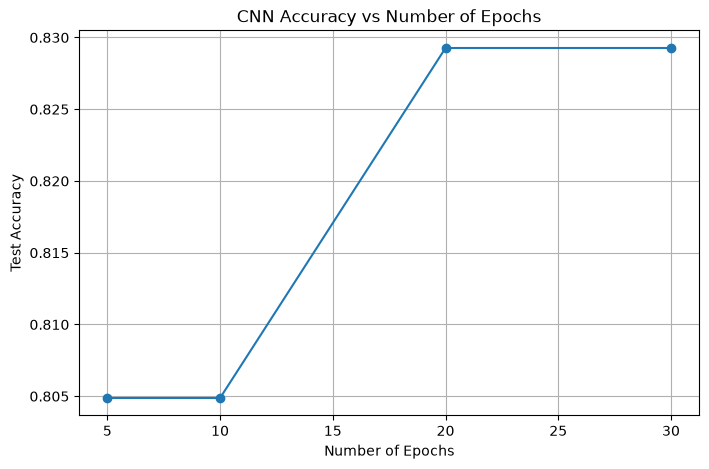

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    epoch_results_df["Epochs"],
    epoch_results_df["Test Accuracy"],
    marker="o"
)

plt.title("CNN Accuracy vs Number of Epochs")
plt.xlabel("Number of Epochs")
plt.ylabel("Test Accuracy")
plt.grid(True)

plt.show()


## 17. Training vs Validation Accuracy

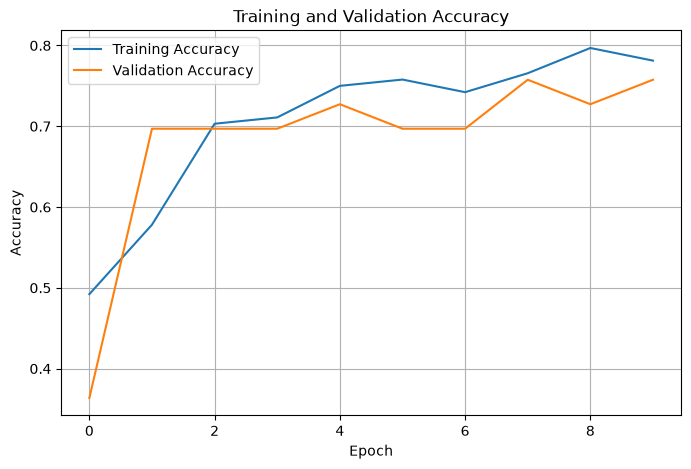

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    history2.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history2.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()


## 18. Training vs Validation Loss

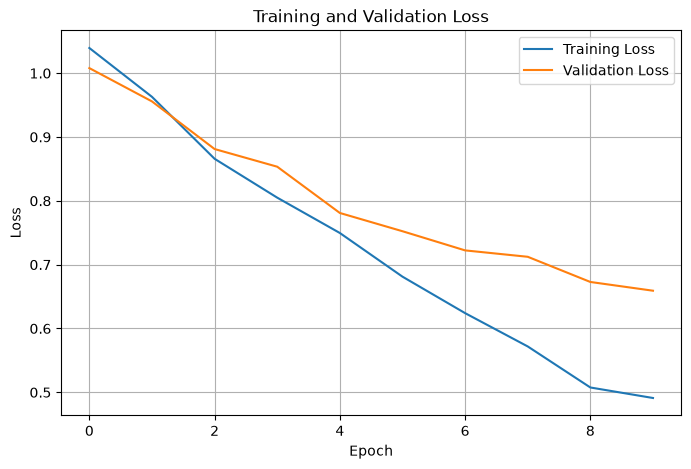

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(
    history2.history["loss"],
    label="Training Loss"
)

plt.plot(
    history2.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()


## 19. Predictions

In [26]:
# Use CNN Configuration 2 for prediction
predictions = model2.predict(X_test_cnn, verbose=0)

predicted_classes = np.argmax(predictions, axis=1)

predicted_labels = label_encoder.inverse_transform(
    predicted_classes
)

actual_labels = label_encoder.inverse_transform(
    y_test
)

prediction_df = pd.DataFrame({
    "Actual": actual_labels,
    "Predicted": predicted_labels
})

display(prediction_df.head(20))


,Actual,Predicted
0,Persian,Persian
1,Pixiebob,Pixiebob
2,Pixiebob,Pixiebob
3,Ragamuffin,Ragamuffin
4,Persian,Persian
5,Pixiebob,Pixiebob
6,Persian,Persian
7,Ragamuffin,Ragamuffin
8,Pixiebob,Pixiebob
9,Ragamuffin,Persian


## 20. Prediction Accuracy and Classification Report

In [27]:
prediction_accuracy = accuracy_score(
    y_test,
    predicted_classes
)

print("Prediction Accuracy:", prediction_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        predicted_classes,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


Prediction Accuracy: 0.8536585365853658

Classification Report:
              precision    recall  f1-score   support

     Persian       0.79      1.00      0.88        19
    Pixiebob       1.00      0.88      0.93        16
  Ragamuffin       0.67      0.33      0.44         6

    accuracy                           0.85        41
   macro avg       0.82      0.74      0.75        41
weighted avg       0.85      0.85      0.84        41



## 21. Final Summary

In [28]:
best_configuration = configuration_results.loc[
    configuration_results["Test Accuracy"].idxmax()
]

best_epoch = epoch_results_df.loc[
    epoch_results_df["Test Accuracy"].idxmax()
]

print("===== FINAL SUMMARY =====")
print("Best CNN Configuration:",
      best_configuration["Configuration"])
print("Best Configuration Accuracy:",
      best_configuration["Test Accuracy"])

print("\nBest Number of Epochs:",
      best_epoch["Epochs"])
print("Best Epoch Accuracy:",
      best_epoch["Test Accuracy"])


===== FINAL SUMMARY =====
Best CNN Configuration: CNN 2 Layers
Best Configuration Accuracy: 0.8536585569381714

Best Number of Epochs: 20.0
Best Epoch Accuracy: 0.8292682766914368


## Conclusion

The experiment compares several 1D CNN configurations and different numbers of epochs.

The best model is selected based on the highest test accuracy. The training/validation accuracy and loss graphs are used to observe the learning behavior of the model.

**Note:** This dataset is tabular data, not a collection of image files. Therefore, this LAB uses a 1D CNN. If the instructor requires image-based 2D CNN, an image dataset should be used instead.
